# 06 · Which distribution fits best at each threshold?

For every threshold we fit three candidate distributions to the waiting
times and compare them in two ways:

* **AIC** (Akaike Information Criterion): likelihood penalised by the number
  of parameters; lower is better. Its uncertainty is estimated by refitting
  on bootstrap resamples of the waiting times.
* **Lilliefors p-value**: a Kolmogorov–Smirnov test whose reference
  distribution is simulated, because the parameters are estimated from the
  same data (see `srb.diagnostics.lilliefors_test`). A small p-value means
  the distribution does not describe the data.

| Model       | Parameters     | Meaning                                    |
|-------------|----------------|--------------------------------------------|
| Exponential | scale          | Poisson process, no memory                 |
| Weibull     | shape, scale   | shape < 1 → clustering of bursts           |
| Gamma       | shape, scale   | shape = 1 is the exponential               |

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from srb.config import FIGURES_DIR, RANDOM_SEED, TABLES_DIR
from srb.data import inter_event_times_by_threshold, load_catalogue, select_thresholds
from srb.diagnostics import bootstrap_aic, bootstrap_summary, lilliefors_test, monte_carlo_p_value_error
from srb.distributions import EXPONENTIAL, GAMMA, WEIBULL
from srb.fitting import fit_mle
from srb.plotting import plot_interevent_histogram_with_fits

## Parameters

In [2]:
START_THRESHOLD = 4000  # SFU
END_THRESHOLD = 100000  # SFU
LILLIEFORS_REPEATS = 10000  # simulations per test (also used for the AIC bootstrap)
MODELS = [WEIBULL, GAMMA, EXPONENTIAL]

In [3]:
df = load_catalogue()
groups = inter_event_times_by_threshold(df, select_thresholds(START_THRESHOLD, END_THRESHOLD))
rng = np.random.default_rng(RANDOM_SEED)

Skipping T = 100000.00: only 6 inter-event times


## Summary table

One row per (threshold, distribution). `*_error`, `*_low`, `*_high` are the
standard error and the 95% interval: from the bootstrap for the AIC, and
from the finite number of simulations for the p-value.

This is the slow step.

In [4]:
rows = []
for threshold, times in groups.items():
    for dist in MODELS:
        p_value, fit = lilliefors_test(times, dist, LILLIEFORS_REPEATS, rng)
        aic_error, aic_low, aic_high = bootstrap_summary(bootstrap_aic(times, dist, LILLIEFORS_REPEATS, rng))
        p_error, p_low, p_high = monte_carlo_p_value_error(p_value, LILLIEFORS_REPEATS)
        rows.append({
            "threshold": threshold,
            "distribution": dist.name,
            "AIC": fit.aic,
            "AIC_error": aic_error,
            "AIC_low": aic_low,
            "AIC_high": aic_high,
            "N": len(times),
            "p_value": p_value,
            "p_value_error": p_error,
            "p_value_low": p_low,
            "p_value_high": p_high,
        })

summary_table = pd.DataFrame(rows)
summary_table.to_csv(TABLES_DIR / "threshold_model_summary.csv", index=False)

In [5]:
print(
    summary_table.to_string(
        index=False,
        formatters={
            "threshold": "{:.0f}".format,
            "AIC": "{:.2f}".format,
            "AIC_error": "{:.2f}".format,
            "AIC_low": "{:.2f}".format,
            "AIC_high": "{:.2f}".format,
            "p_value": "{:.4g}".format,
            "p_value_error": "{:.4g}".format,
            "p_value_low": "{:.4g}".format,
            "p_value_high": "{:.4g}".format,
        },
    )
)

threshold distribution     AIC AIC_error AIC_low AIC_high   N   p_value p_value_error p_value_low p_value_high
     4281      Weibull 1645.46     85.34 1473.06  1804.33 183    0.0011     0.0003315   0.0004502      0.00175
     4281        Gamma 1638.73     83.81 1468.94  1798.15 183     0.035      0.001838     0.03139       0.0386
     4281  Exponential 2111.86     60.25 1983.06  2218.18 183 9.999e-05     9.999e-05           0     0.000296
     5456      Weibull 1460.21     84.05 1287.82  1615.28 161 9.999e-05     9.999e-05           0     0.000296
     5456        Gamma 1450.50     82.77 1281.46  1608.71 161   0.08879      0.002844     0.08322      0.09437
     5456  Exponential 1899.46     56.72 1778.45  2000.36 161 9.999e-05     9.999e-05           0     0.000296
     6952      Weibull 1227.62     77.01 1070.71  1371.95 128 9.999e-05     9.999e-05           0     0.000296
     6952        Gamma 1214.24     75.69 1060.45  1356.42 128    0.2478      0.004317      0.2393       0.2562
 

## Visual check at the lowest threshold

Histogram of the waiting times with logarithmic bins (error bars are
Poisson, √count) and the three fitted densities. A straight line on a
log-log plot over several decades is the signature of a heavy tail, which
the exponential cannot reproduce.

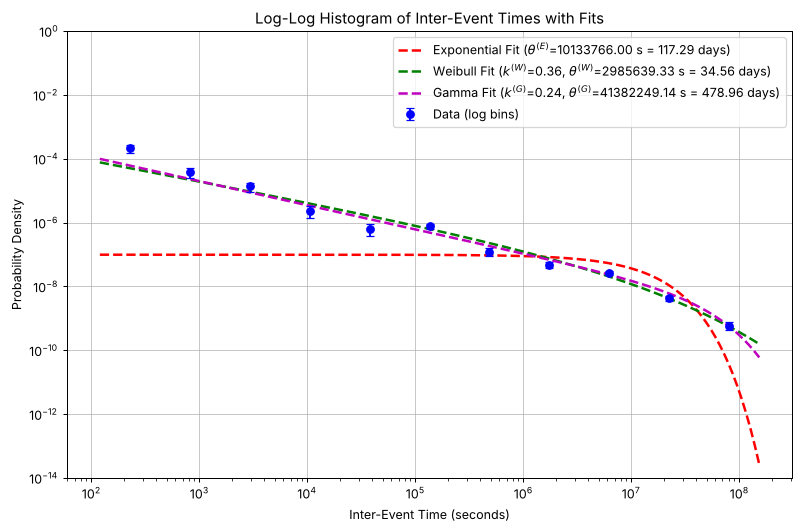

In [6]:
lowest_threshold = min(groups)
times = groups[lowest_threshold]
fits = [fit_mle(times, dist) for dist in [EXPONENTIAL, WEIBULL, GAMMA]]

fig = plot_interevent_histogram_with_fits(times, fits)
fig.savefig(FIGURES_DIR / "interevent_histogram_with_fits.png", dpi=200)
plt.show()